# Conference scheduling

Harbor Data Days is a fictional two-day conference with three talk rooms, a hands-on lab and four
tracks. The program committee has accepted its talks. Now it has to decide **which talk goes in which
room at which time**, so that no speaker is double-booked, popular talks get big rooms, and people
following one track do not have to pick between two of its talks.

In this notebook you will:

1. describe the conference as Python objects,
2. solve it and print the program,
3. check the result yourself, without trusting the solver's score,
4. change a rule and see what the program gives up in return,
5. accept more talks and find where the rooms run out,
6. repair a published program after a change, and restart the search from an existing program.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import textwrap
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle

from optimaru import conference_scheduling as cs
from optimaru.conference_scheduling.constraints import ThemeTrackConflict, get_constraints
from optimaru.conference_scheduling.models import ConferenceScheduleModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the conference

| Object | What it holds |
| --- | --- |
| `Timeslot` | start and end in minutes from a shared origin, accepted talk types, tags such as `After lunch` |
| `Room` | capacity, the talk types it accepts, closed timeslots, tags such as `Recorded` |
| `Speaker` | unavailable timeslots, and required, preferred or undesired tags |
| `Talk` | type, speakers, track, topic, audience level, expected audience, prerequisites, tag rules |

Two days at 1440 minutes each share one clock, so `1440 + 9 * 60` is 09:00 on the second day. Talks
last 45 minutes. Labs last 90, in the lab room, and so they overlap talks in the other rooms. Speakers,
prerequisites and timeslots refer to each other by **list position**.

Each day has six talk slots in three rooms, so the conference has 36 cells for talks. The four labs
fill the four lab cells exactly, and three of them require a talk of their track to come first. The
two keynotes are pinned: they start with a fixed `slot_room` and the search never moves them.

In [2]:
TALK, LAB = 0, 1
DAY_MINUTES = 1440
TRACKS = ["Optimization", "Data", "Cloud", "Product"]
TRACK_COLOR = dict(zip(TRACKS, COLORS)) | {"Keynote": "#c3c2b7"}
TOPICS = {
    "Optimization": ["Routing", "Scheduling", "Modeling"],
    "Data": ["Pipelines", "Forecasting", "Quality"],
    "Cloud": ["Costs", "Reliability", "Scaling"],
    "Product": ["Research", "Pricing", "Teams"],
}
TITLES = {
    "Optimization": ["Routing at city scale", "Shift rosters that stick", "Local search in practice",
                     "Modeling with soft rules", "Warehouse slotting", "Fleet sizing by simulation",
                     "Pricing a delivery window", "Explaining a schedule", "Benchmarks that mislead",
                     "Repair over re-solve"],
    "Data": ["Pipelines that heal", "Forecasts for small shops", "Data contracts", "Testing a feature store",
             "Late data, on time", "Cleaning sensor logs", "Metrics nobody reads", "Event streams at rest",
             "Sampling for audits", "Lineage on a budget"],
    "Cloud": ["Cutting the compute bill", "Scaling without surprises", "Postmortems that teach",
              "Zero-downtime moves", "Multi-region trade-offs", "Cold starts measured", "Secrets in the open",
              "Observability on a diet", "Capacity by calendar", "Autoscaling myths"],
    "Product": ["Research in two weeks", "Roadmaps without dates", "Pricing experiments", "Onboarding that lasts",
                "Killing a feature", "Interviews at scale", "Writing for operators", "Support as a sensor",
                "Small teams, big scope", "Shipping the boring part"],
}
LABS = [("Hands-on routing", "Optimization"), ("Build a pipeline", "Data"),
        ("Load-test a service", "Cloud"), ("Run a usability test", "Product")]
SPEAKER_NAMES = ("Ada Moss,Ben Hart,Cleo Vance,Dev Rao,Elin Sand,Finn Doyle,Gia Marsh,Hugo Lind,Ines Roth,Jon Pike,"
                 "Kira Wolfe,Leo Stone,Mina Ross,Noor Hale,Omar Reed,Pia Quinn,Quin Blake,Rosa Lane,Sami Holt,"
                 "Tess Cole,Uma Frost,Vic Shaw").split(",")


def clock(day, hour, minute=0):
    return day * DAY_MINUTES + hour * 60 + minute


def make_timeslots():
    slots = []
    for day in (0, 1):
        day_tag = f"Day {day + 1}"
        for k, (hour, minute) in enumerate([(9, 0), (10, 0), (11, 0), (13, 30), (14, 30), (15, 30)]):
            tags = [day_tag] + (["After lunch"] if k == 3 else [])
            start = clock(day, hour, minute)
            slots.append(cs.Timeslot(f"D{day + 1}-{hour:02d}{minute:02d}", start, start + 45, [TALK], tags))
        for hour, minute in [(9, 0), (14, 30)]:
            start = clock(day, hour, minute)
            slots.append(cs.Timeslot(f"D{day + 1}-lab{hour:02d}", start, start + 90, [LAB], [day_tag]))
    return slots


def make_schedule(talk_count=28):
    """A fresh, unsolved conference. Solvers work in place, so each experiment gets its own.

    talk_count is the number of accepted talks on top of the two keynotes and four labs. Random draws
    happen per talk in acceptance order, so accepting more talks keeps the earlier ones unchanged.
    """
    rng = np.random.default_rng(11)
    timeslots = make_timeslots()
    rooms = [
        cs.Room("HALL", "Main Hall", 400, [TALK], [], ["Recorded", "Large"]),
        cs.Room("BAY", "Bay Room", 180, [TALK], [], ["Recorded"]),
        cs.Room("DOCK", "Dock Room", 90, [TALK], [], []),
        cs.Room("LAB", "Lab", 40, [LAB], [], []),
    ]
    speakers = [cs.Speaker(f"S{k:02d}", name) for k, name in enumerate(SPEAKER_NAMES)]
    day_slots = {tag: [i for i, s in enumerate(timeslots) if tag in s.tags] for tag in ("Day 1", "Day 2")}
    speakers[2].unavailable_timeslots = day_slots["Day 2"]  # leaves after the first day
    speakers[5].unavailable_timeslots = day_slots["Day 1"]  # arrives for the second day
    speakers[7].undesired_timeslot_tags = ["After lunch"]

    def speaker_ids():
        ids = [int(rng.integers(len(SPEAKER_NAMES)))]
        if rng.random() < 0.2:
            ids.append(int(rng.integers(len(SPEAKER_NAMES))))
        return sorted(set(ids))

    def new_talk(code, title, track, talk_type=TALK):
        ids, topic = speaker_ids(), str(rng.choice(TOPICS[track]))
        favorites = int(rng.integers(40, 400))
        return cs.Talk(code=code, title=title, talk_type=talk_type, speakers=ids, theme_track_tags=[track],
                       sector_tags=[str(rng.choice(["Retail", "Logistics", "Finance"]))],
                       audience_types=[str(rng.choice(["Engineers", "Analysts", "Managers"]))],
                       audience_level=int(rng.integers(1, 4)), content_tags=[topic], favorite_count=favorites,
                       required_room_tags=["Recorded"] if favorites > 350 else [])

    talks = [cs.Talk(code=f"K{k + 1}", title=f"{name} keynote", speakers=[k], favorite_count=500,
                     required_room_tags=["Large"]) for k, name in enumerate(["Opening", "Closing"])]
    for k in range(talk_count):
        track = TRACKS[k % 4]
        talks.append(new_talk(f"T{k + 1:02d}", TITLES[track][k // 4], track))
    for k, (title, track) in enumerate(LABS):
        talks.append(new_talk(f"L{k + 1}", title, track, LAB))
        if k < 3:  # one lab must run on the first morning, before any talk has ended
            talks[-1].prerequisite_talks = [2 + k]  # the first talk of the same track

    schedule = cs.ConferenceSchedule("harbor-data-days", ["Talk", "Lab"], timeslots, rooms, speakers, talks)
    for talk, slot in [(schedule.talks[0], "D1-0900"), (schedule.talks[1], "D2-1530")]:
        talk.slot_room = schedule.slot_room_of([s.id for s in timeslots].index(slot), 0)
        talk.pinned = True
    return schedule


schedule = make_schedule()
print(f"{schedule.talk_count()} talks, {schedule.timeslot_count()} timeslots, {schedule.room_count()} rooms, "
      f"{len(schedule.speakers)} speakers, {schedule.slot_room_count()} (timeslot, room) values")

34 talks, 16 timeslots, 4 rooms, 22 speakers, 64 (timeslot, room) values


`Talk.slot_room` is the one decision: a single integer holding a timeslot and a room at once. Use
`timeslot_index_of` and `room_index_of` to read it, and `slot_room_of` to write it. Before solving,
here is what the committee accepted, by track and level.

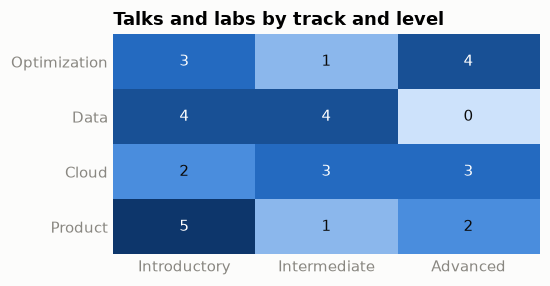

In [3]:
def track_of(talk):
    return talk.theme_track_tags[0] if talk.theme_track_tags else "Keynote"


counts = np.zeros((len(TRACKS), 3), dtype=int)
for talk in schedule.talks:
    if talk.theme_track_tags:
        counts[TRACKS.index(track_of(talk)), talk.audience_level - 1] += 1

ramp = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.imshow(counts, cmap=ramp, aspect="auto", vmin=0)
for (row, col), value in np.ndenumerate(counts):
    ax.text(col, row, value, ha="center", va="center", color="white" if value > counts.max() / 2 else "#0b0b0b")
ax.set_xticks(range(3), ["Introductory", "Intermediate", "Advanced"])
ax.set_yticks(range(len(TRACKS)), TRACKS)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("Talks and labs by track and level")
plt.show()

## 2. Solve it

`cs.solve` works in place: `slot_room` and the score are written back onto `schedule`. The score has two
levels, compared in order:

- **hard**: minus the weighted minutes of broken rules, where `0` means the program is feasible
- **soft**: rewards minus penalties. Higher is better, and it usually stays negative because
  many preferences pull against each other

By default one solve runs as eight consecutive short searches (`restart_segments`), each continuing
from the best program so far, and they share the time limit.

In [4]:
TIME_LIMIT = 3
SEED = 1

cs.solve(schedule, time_limit_seconds=TIME_LIMIT, random_seed=SEED)

print("feasible:", schedule.score.is_feasible())
print("score   :", schedule.score.hard, "/", schedule.score.soft)

feasible: True
score   : 0 / -170520.0


`constraint_costs` returns the raw cost of every rule with its weight, so you can see where a score
comes from.

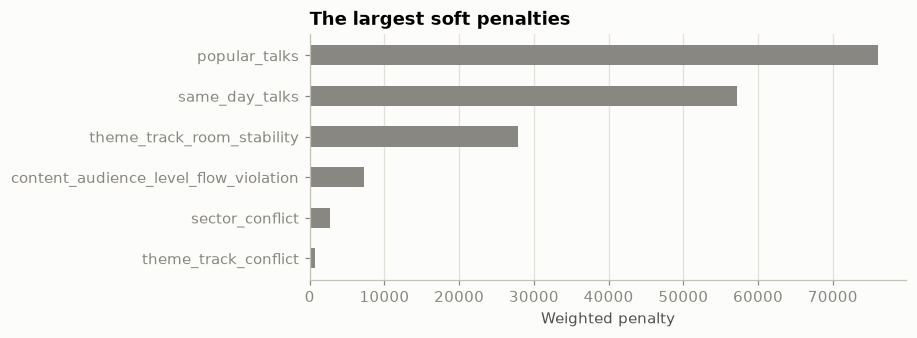

In [5]:
raw = cs.constraint_costs(schedule)
terms = {name: entry["weight"] * sum(entry["costs"]) for name, entry in raw.items() if not entry["hard"]}
assert -sum(terms.values()) == schedule.score.soft

largest = sorted((name for name in terms if terms[name] > 0), key=terms.get)[-6:]
fig, ax = plt.subplots(figsize=(7, 2.9))
ax.barh(largest, [terms[name] for name in largest], height=0.5, color=MUTED)
ax.set(title="The largest soft penalties", xlabel="Weighted penalty")
ax.grid(True, axis="x")
plt.show()

### The program

This is the page attendees would read: rooms as columns, real time running down, talks colored by
track. Labs are 90 minutes long, so they cross the talk rows.

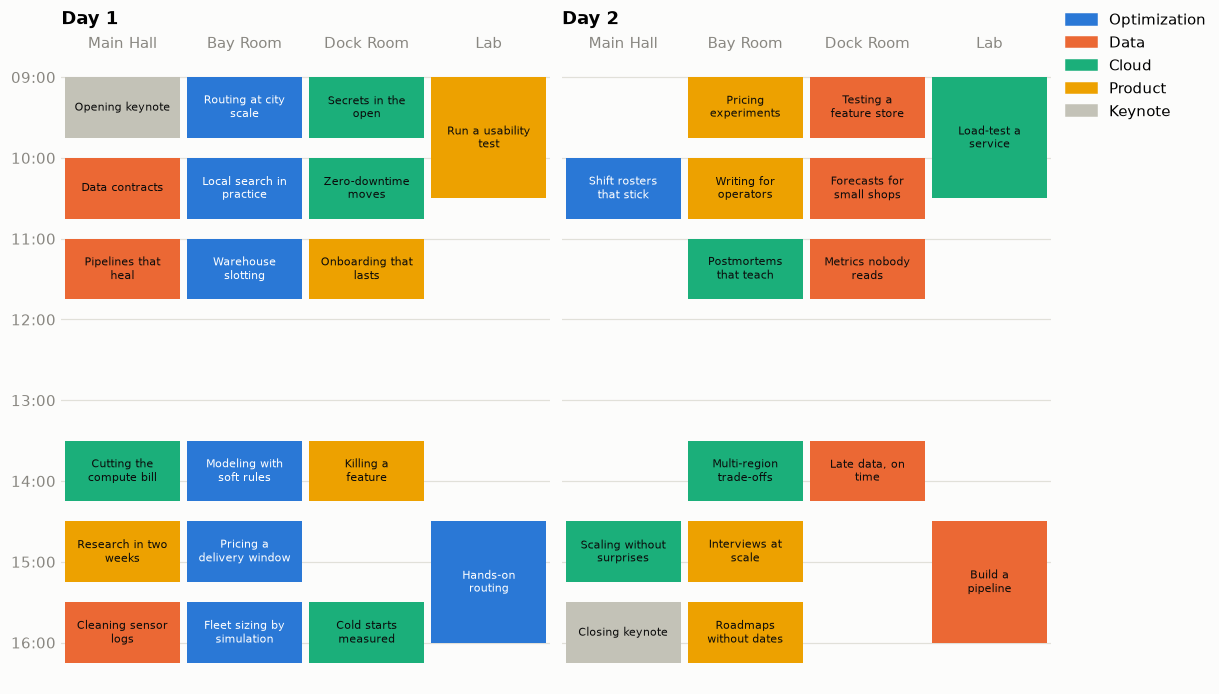

In [6]:
def where(schedule, talk):
    """Timeslot and room objects of a placed talk."""
    return (schedule.timeslots[schedule.timeslot_index_of(talk.slot_room)],
            schedule.rooms[schedule.room_index_of(talk.slot_room)])


def draw_program(schedule):
    fig, axes = plt.subplots(1, 2, figsize=(11, 6.2), sharey=True, layout="constrained")
    for day, ax in enumerate(axes):
        for talk in schedule.talks:
            slot, room = where(schedule, talk)
            if slot.start_minute // DAY_MINUTES != day:
                continue
            column = [r.id for r in schedule.rooms].index(room.id)
            start = (slot.start_minute % DAY_MINUTES) / 60
            hours = (slot.end_minute - slot.start_minute) / 60
            track = track_of(talk)
            ax.add_patch(Rectangle((column + 0.03, start), 0.94, hours, facecolor=TRACK_COLOR[track],
                                   edgecolor="none"))
            label = "\n".join(textwrap.wrap(talk.title, 15)[:3])
            ax.text(column + 0.5, start + hours / 2, label, ha="center", va="center", fontsize=7,
                    color="white" if track == "Optimization" else "#0b0b0b")
        ax.set_xlim(0, len(schedule.rooms))
        ax.set_xticks(np.arange(len(schedule.rooms)) + 0.5, [r.name for r in schedule.rooms])
        ax.xaxis.tick_top()
        ax.tick_params(length=0)
        ax.set_title(f"Day {day + 1}", pad=8)
        ax.grid(True, axis="y")
        ax.spines[["left", "bottom"]].set_visible(False)
    axes[0].set_ylim(16.5, 8.75)
    axes[0].set_yticks(range(9, 17), [f"{h:02d}:00" for h in range(9, 17)])
    fig.legend(handles=[Patch(color=TRACK_COLOR[t], label=t) for t in TRACK_COLOR], loc="outside right upper")
    plt.show()


draw_program(schedule)

### Do the popular talks get the big rooms?

`favorite_count` is how many attendees marked a talk. The `popular_talks` rule compares talks by room
capacity and favorites. It only ranks them, and never checks a talk against its room's capacity, so
the black tick is there for you to read: talks above it may overflow the room.

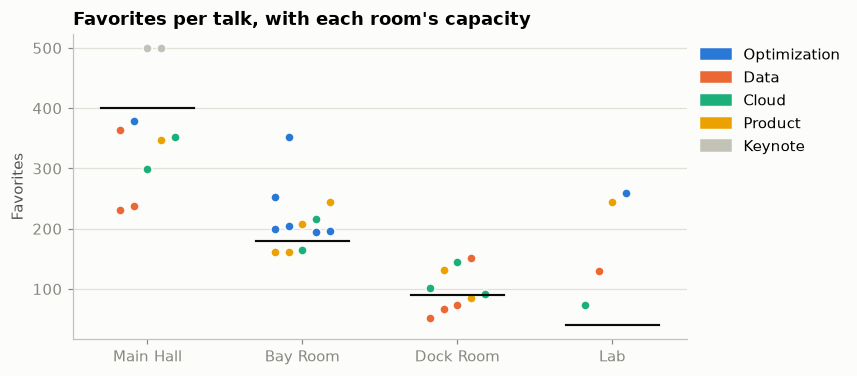

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for column, room in enumerate(schedule.rooms):
    ax.plot([column - 0.3, column + 0.3], [room.capacity] * 2, color="#0b0b0b", linewidth=1.4)
    in_room = [talk for talk in schedule.talks if where(schedule, talk)[1].id == room.id]
    for k, talk in enumerate(sorted(in_room, key=lambda t: t.favorite_count)):
        ax.scatter(column + (k % 5 - 2) * 0.09, talk.favorite_count, s=36, color=TRACK_COLOR[track_of(talk)],
                   edgecolor="#fcfcfb", linewidth=1)
ax.set_xticks(range(len(schedule.rooms)), [r.name for r in schedule.rooms])
ax.set(title="Favorites per talk, with each room's capacity", ylabel="Favorites")
ax.grid(True, axis="y")
ax.legend(handles=[Patch(color=TRACK_COLOR[t], label=t) for t in TRACK_COLOR],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

Six of the hard rules are recomputed here from `slot_room` alone. Minutes are counted the way the score
counts them, so each recount can be compared with the solver's own breakdown.

In [8]:
def overlap(a, b):
    return max(0, min(a.end_minute, b.end_minute) - max(a.start_minute, b.start_minute))


def recount_hard_rules(schedule):
    report = Counter()
    placed = [(talk, *where(schedule, talk)) for talk in schedule.talks]
    for talk, slot, room in placed:
        minutes = slot.end_minute - slot.start_minute
        mismatches = (talk.talk_type not in slot.talk_types) + (talk.talk_type not in room.talk_types)
        report["talk_type_compatibility"] += mismatches * max(minutes, 1)
        report["talk_required_room_tags"] += len(set(talk.required_room_tags) - set(room.tags)) * minutes
        for speaker in talk.speakers:
            if schedule.timeslots.index(slot) in schedule.speakers[speaker].unavailable_timeslots:
                report["speaker_unavailable_timeslot"] += minutes
    for i, (a, slot_a, room_a) in enumerate(placed):
        for b, slot_b, room_b in placed[i + 1:]:
            minutes = overlap(slot_a, slot_b)
            if room_a.id == room_b.id:
                report["room_conflict"] += minutes
            report["speaker_conflict"] += minutes * len(set(a.speakers) & set(b.speakers))
    for talk, slot, _ in placed:
        for position in talk.prerequisite_talks:
            first = where(schedule, schedule.talks[position])[0]
            if first.end_minute > slot.start_minute:
                report["talk_prerequisite_talks"] += (first.end_minute - first.start_minute
                                                      + slot.end_minute - slot.start_minute)
    return report


recount = recount_hard_rules(schedule)
breakdown = cs.compute_breakdown(schedule)
for rule in ("talk_type_compatibility", "talk_required_room_tags", "room_conflict", "speaker_conflict",
             "speaker_unavailable_timeslot", "talk_prerequisite_talks"):
    print(f"{rule:30s}recounted {recount[rule]:3d}   solver {getattr(breakdown, rule)}")

print("\nkeynotes:", [(t.code, where(schedule, t)[0].id, where(schedule, t)[1].name) for t in schedule.talks[:2]])
print("every talk placed:", all(t.slot_room >= 0 for t in schedule.talks))

talk_type_compatibility       recounted   0   solver 0
talk_required_room_tags       recounted   0   solver 0
room_conflict                 recounted   0   solver 0
speaker_conflict              recounted   0   solver 0
speaker_unavailable_timeslot  recounted   0   solver 0
talk_prerequisite_talks       recounted   0   solver 0

keynotes: [('K1', 'D1-0900', 'Main Hall'), ('K2', 'D2-1530', 'Main Hall')]
every talk placed: True


## 4. Change the rules

Every rule is a plugin. `get_constraints()` returns the default list, and only what you pass to
`solve(constraints=...)` is scored, so swap a rule rather than listing just the new one.

In [9]:
print(textwrap.fill(", ".join(cs.list_constraints()), 100))

talk_type_compatibility, room_unavailable_timeslot, room_conflict, speaker_unavailable_timeslot,
speaker_conflict, talk_prerequisite_talks, talk_mutually_exclusive_talks_tags,
consecutive_talks_pause, crowd_control, speaker_required_timeslot_tags,
speaker_prohibited_timeslot_tags, talk_required_timeslot_tags, talk_prohibited_timeslot_tags,
speaker_required_room_tags, speaker_prohibited_room_tags, talk_required_room_tags,
talk_prohibited_room_tags, theme_track_conflict, theme_track_room_stability, sector_conflict,
audience_type_theme_track_conflict, content_audience_level_flow_violation, content_conflict,
same_day_talks, popular_talks, speaker_preferred_timeslot_tags, speaker_undesired_timeslot_tags,
talk_preferred_timeslot_tags, talk_undesired_timeslot_tags, speaker_preferred_room_tags,
speaker_undesired_room_tags, talk_preferred_room_tags, talk_undesired_room_tags, speaker_makespan,
audience_type_diversity, audience_level_diversity, language_diversity


By default a clash between two talks of one track costs far less than the pull to keep a track on one
day, so attendees can still face two talks of their own track at once. Raising the weight of
`theme_track_conflict` from 10 to 100 asks the solver to spread each track out in time. `weight` scales a
rule, `hard` moves it between levels, and `exponent=2` makes large violations much costlier.

One run could be luck, so both versions run with the same four seeds. Each line joins one seed.

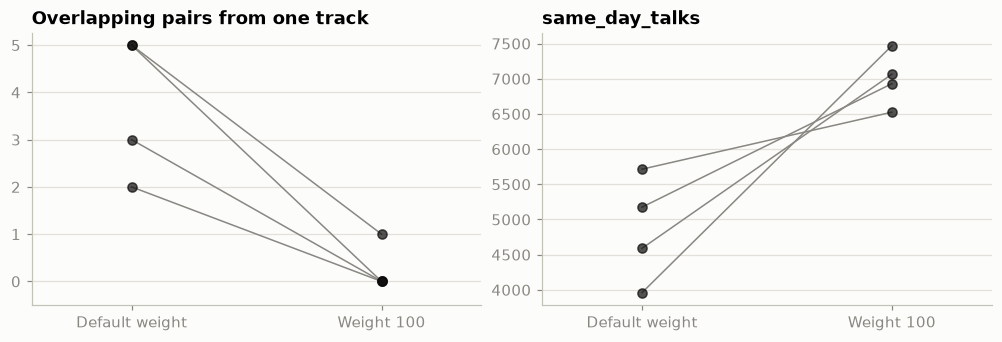

Default weight  per seed (clashing pairs, same_day_talks, hard): [(2, 5715, 0), (3, 5175, 0), (5, 3960, 0), (5, 4590, 0)]
Weight 100      per seed (clashing pairs, same_day_talks, hard): [(0, 6525, 0), (0, 6930, 0), (0, 7470, 0), (1, 7065, 0)]


In [10]:
def replaced(*specs):
    names = {spec.name for spec in specs}
    return [c for c in get_constraints() if c.name not in names] + list(specs)


def track_clashes(schedule):
    """Pairs of talks of one track that overlap in time, per track."""
    clashes = Counter()
    placed = [(talk, where(schedule, talk)[0]) for talk in schedule.talks if talk.theme_track_tags]
    for i, (a, slot_a) in enumerate(placed):
        for b, slot_b in placed[i + 1:]:
            if track_of(a) == track_of(b) and overlap(slot_a, slot_b):
                clashes[track_of(a)] += 1
    return clashes


SEEDS = (1, 2, 3, 4)
results = {"Default weight": [], "Weight 100": []}
for seed in SEEDS:
    default_run, reweighted = make_schedule(), make_schedule()
    cs.solve(default_run, time_limit_seconds=1.5, random_seed=seed)
    cs.solve(reweighted, time_limit_seconds=1.5, random_seed=seed,
             constraints=replaced(ThemeTrackConflict(weight=100)))
    for label, run in [("Default weight", default_run), ("Weight 100", reweighted)]:
        same_day = cs.compute_breakdown(run).same_day_talks
        results[label].append((sum(track_clashes(run).values()), same_day, run.score.hard))

fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
for ax, column, title in [(axes[0], 0, "Overlapping pairs from one track"), (axes[1], 1, "same_day_talks")]:
    for k in range(len(SEEDS)):
        ax.plot([0, 1], [results[label][k][column] for label in results], color=MUTED, linewidth=1, zorder=1)
    for x, label in enumerate(results):
        ax.scatter([x] * len(SEEDS), [run[column] for run in results[label]], s=36, color="#0b0b0b",
                   alpha=0.7, zorder=2)
    ax.set_xticks([0, 1], list(results))
    ax.set_xlim(-0.4, 1.4)
    ax.set_title(title)
    ax.grid(True, axis="y")
axes[0].yaxis.get_major_locator().set_params(integer=True)
axes[0].set_ylim(-0.5, None)
plt.show()

for label, runs in results.items():
    print(f"{label:16s}per seed (clashing pairs, same_day_talks, hard): {runs}")

Soft scores from two different rule sets are not comparable, because the weights differ. Compare what
happened to the program instead: `same_day_talks` is the price attendees pay when a track is spread over
both days, so read it against the clash count. A constraint list runs as one search rather than the
default eight, and a higher weight still does not make a rule absolute. Use `hard=True` for that.

## 5. How many talks can we accept?

The committee has more good submissions. Each extra talk fills a cell, which leaves less room to keep a
track apart. Counting gives the limit before any solve: the two keynotes also use talk cells, so once
talks exceed the 36 cells, no program exists, however long the search runs. Below that limit the
question is how much quality each extra talk costs. Each case runs with two seeds, and each dot is one
run.

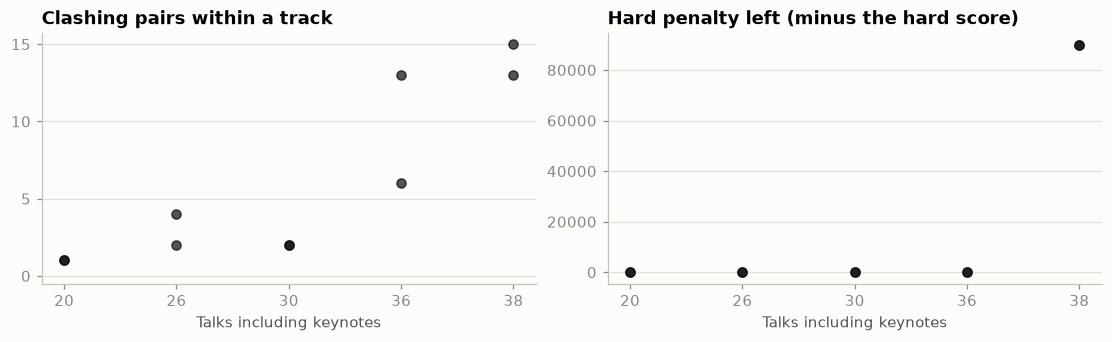

20 talks for 36 cells: per seed (clashing pairs, hard score) [(1, 0), (1, 0)]
26 talks for 36 cells: per seed (clashing pairs, hard score) [(2, 0), (4, 0)]
30 talks for 36 cells: per seed (clashing pairs, hard score) [(2, 0), (2, 0)]
36 talks for 36 cells: per seed (clashing pairs, hard score) [(6, 0), (13, 0)]
38 talks for 36 cells: per seed (clashing pairs, hard score) [(13, -90000), (15, -90000)]


In [11]:
CELLS = 36
accepted = [18, 24, 28, 34, 36]
runs = {}
for count in accepted:
    runs[count] = []
    for seed in (1, 2):
        case = make_schedule(count)
        cs.solve(case, time_limit_seconds=1, random_seed=seed)
        runs[count].append((sum(track_clashes(case).values()), case.score.hard))

x = np.arange(len(accepted))
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
for k, count in enumerate(accepted):
    axes[0].scatter([k, k], [clashes for clashes, _ in runs[count]], s=36, color="#0b0b0b", alpha=0.7)
    axes[1].scatter([k, k], [-hard for _, hard in runs[count]], s=36, color="#0b0b0b", alpha=0.7)
axes[0].set(title="Clashing pairs within a track", ylim=(-0.5, None))
axes[0].yaxis.get_major_locator().set_params(integer=True)
axes[1].set(title="Hard penalty left (minus the hard score)")
for ax in axes:
    ax.set_xticks(x, [count + 2 for count in accepted])
    ax.set_xlabel("Talks including keynotes")
    ax.grid(True, axis="y")
plt.show()

for count in accepted:
    print(f"{count + 2:2d} talks for {CELLS} cells: per seed (clashing pairs, hard score) {runs[count]}")

A hard score below zero with more talks than cells comes from the count above, not from the search.
Inside the limit, compare the dots across cases, and treat a gap between two runs of one case as search
noise.

## 6. Repair a published program

Solved programs move between runs as `ConferenceScheduleModel`, a pydantic mirror of the engine
objects. `with_initial_solution(problem, solution)` copies a problem and starts its search from that
solution, and `to_core()` turns it back into what `solve` takes.

After the program is published, the speaker of the most popular talk outside the keynotes loses that talk's timeslot. With a
time limit of `0` you get the old program back, scored against the new fact.

In [12]:
problem = ConferenceScheduleModel.from_core(make_schedule())
published = ConferenceScheduleModel.from_core(schedule)

star = max((t for t in schedule.talks if t.talk_type == TALK and not t.pinned), key=lambda t: t.favorite_count)
star_slot = schedule.timeslot_index_of(star.slot_room)
star_day = schedule.timeslots[star_slot].start_minute // DAY_MINUTES


def changed_problem():
    model = problem.model_copy(deep=True)
    speaker = model.speakers[star.speakers[0]]
    speaker.unavailable_timeslots = sorted({*speaker.unavailable_timeslots, star_slot})
    return model


def talks_moved(result):
    return sum(a.slot_room != b.slot_room for a, b in zip(result.talks, published.talks))


old = cs.with_initial_solution(changed_problem(), published).to_core()
cs.solve(old, time_limit_seconds=0, random_seed=SEED)
print(f"{star.title}: speaker {SPEAKER_NAMES[star.speakers[0]]} loses {schedule.timeslots[star_slot].id}")
print("the published program under the new fact:", old.score.hard, "/", old.score.soft)

Shift rosters that stick: speaker Finn Doyle loses D2-1000
the published program under the new fact: -4500 / -170520.0


A warm start begins at the published program, but the search may then move any talk that is not pinned.
If attendees have already planned around one day, pin the other day: set `pinned=True` on the problem,
with the published `slot_room`. The three strategies are compared on what changed and on what the
program ends up scoring.

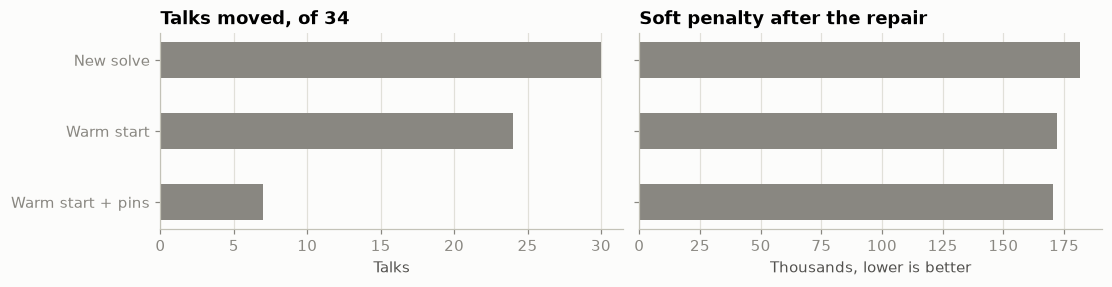

New solve         hard 0, soft -181485, moved 30
Warm start        hard 0, soft -172125, moved 24
Warm start + pins hard 0, soft -170385, moved 7


In [13]:
def pinned_problem():
    model = changed_problem()
    for talk, old_talk in zip(model.talks, published.talks):
        timeslot = schedule.timeslot_index_of(old_talk.slot_room)
        if schedule.timeslots[timeslot].start_minute // DAY_MINUTES != star_day:
            talk.slot_room, talk.pinned = old_talk.slot_room, True
    return model


repairs = {
    "New solve": changed_problem().to_core(),
    "Warm start": cs.with_initial_solution(changed_problem(), published).to_core(),
    "Warm start + pins": cs.with_initial_solution(pinned_problem(), published).to_core(),
}
for result in repairs.values():
    cs.solve(result, time_limit_seconds=2, random_seed=5)

names = list(repairs)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True, layout="constrained")
axes[0].barh(names, [talks_moved(r) for r in repairs.values()], height=0.5, color=MUTED)
axes[0].set(title=f"Talks moved, of {schedule.talk_count()}", xlabel="Talks")
axes[1].barh(names, [-r.score.soft / 1000 for r in repairs.values()], height=0.5, color=MUTED)
axes[1].set(title="Soft penalty after the repair", xlabel="Thousands, lower is better")
axes[0].invert_yaxis()
for ax in axes:
    ax.grid(True, axis="x")
plt.show()

for name, result in repairs.items():
    print(f"{name:18s}hard {result.score.hard}, soft {result.score.soft:.0f}, moved {talks_moved(result)}")

### Keep improving a program

You can also restart from a result to spend more time on it. **Give each round its own `random_seed`.**
The same start with the same seed repeats the same search, so a round that found nothing will find
nothing again.

On this use case a new seed is no guarantee either. A search that reaches a good program tends to stop
improving early, and a new seed can hand the same program back. Very short rounds do least, because
each one is split into `restart_segments` searches. That is why the rounds below are 1 second long, and
why the right-hand chart also shows solves from scratch with other seeds, on the same axis. If the
lines stay flat and the dots reach higher, new seeds from scratch are the better use of your time.

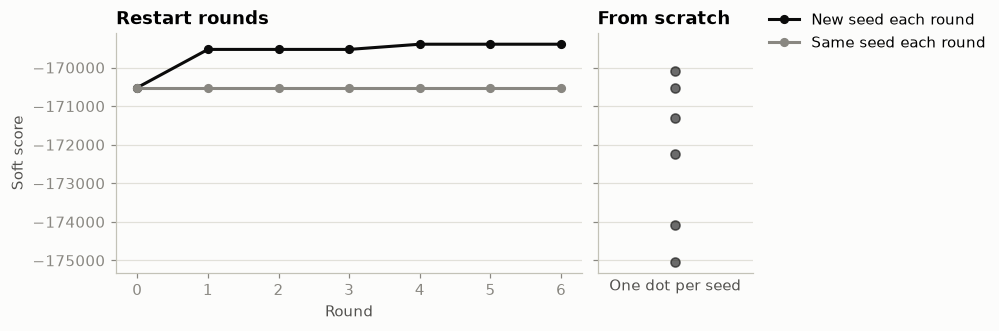

new seed     : [-170520.0, -169530.0, -169530.0, -169530.0, -169395.0, -169395.0, -169395.0]
same seed    : [-170520.0, -170520.0, -170520.0, -170520.0, -170520.0, -170520.0, -170520.0]
from scratch : [-172245.0, -174075.0, -171315.0, -170535.0, -175035.0, -170085.0]


In [14]:
def rounds(seeds):
    current, history = published, [published.score_soft]
    for seed in seeds:
        restart = cs.with_initial_solution(problem, current).to_core()
        cs.solve(restart, time_limit_seconds=1, random_seed=seed)
        current = ConferenceScheduleModel.from_core(restart)
        history.append(restart.score.soft)
    return history


new_seeds = rounds(range(2, 8))
same_seed = rounds([SEED] * 6)
scratch = []
for seed in range(2, 8):
    fresh = make_schedule()
    cs.solve(fresh, time_limit_seconds=1, random_seed=seed)
    scratch.append(fresh.score.soft if fresh.score.is_feasible() else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(9, 2.9), sharey=True, width_ratios=[3, 1], layout="constrained")
axes[0].plot(new_seeds, color="#0b0b0b", linewidth=2, marker="o", markersize=5, label="New seed each round")
axes[0].plot(same_seed, color=MUTED, linewidth=2, marker="o", markersize=5, label="Same seed each round")
axes[0].set(title="Restart rounds", xlabel="Round", ylabel="Soft score")
axes[1].scatter(np.zeros(len(scratch)), scratch, s=36, color="#0b0b0b", alpha=0.6)
axes[1].set_xticks([])
axes[1].set(title="From scratch", xlabel="One dot per seed")
for ax in axes:
    ax.grid(True, axis="y")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right upper")
plt.show()

print("new seed     :", new_seeds)
print("same seed    :", same_seed)
print("from scratch :", scratch)

All of these scores are the best found in the time limit, not proven optima.

## Next steps

- `Talk` also takes `mutually_exclusive_talks_tags` and `crowd_control_risk`, and speakers
  and talks take required, preferred, prohibited and undesired tags for timeslots and rooms.
- `use-cases/conference-scheduling/README.md` covers solver options and how to add moves and constraints
  in C++.
- For a weekly grid of lessons with classes and teachers, see `school-timetabling.ipynb`.